# 05 — Learning: from the loss to gradients, then to updating `W`

**Chapter 1** · suggested time: 25 min · CPU only · [![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zenocode-org/ai-masterclass/blob/main/en/chapter_1/05_gradients_and_update.ipynb)

![Chapter roadmap](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/00_roadmap.png)

The network can do its **forward pass**: for each current character, it produces 27 probabilities. We know how to **measure** its error with the NLL.

**But measuring is not enough to learn.** `W` is still random: how do we change its 729 numbers so that the correct answers become more likely?

Four problems to solve, in order:
1. **Which probability do we evaluate?** The one of the correct answer, in each row: `probs[torch.arange(n), ys]`.
2. **Which weight do we change, and in which direction?** That is what the derivatives tell us, stored in `W.grad` by `loss.backward()`.
3. **By how much?** That is the job of the *learning rate*.
4. **How do we learn on the whole corpus?** By repeating all of this in a loop (notebook 06).

> **Goal:** be able to explain **every line** of the training loop, not just run it.

In [1]:
# On Google Colab: fetch the course repository (corpus + shared modules such as bigram.py).
# Locally, this cell does nothing.
import os, sys
if "google.colab" in sys.modules and not os.path.exists("bigram.py"):
    if not os.path.exists("ai-masterclass"):
        !git clone -q --depth 1 https://github.com/zenocode-org/ai-masterclass
    %cd ai-masterclass/en/chapter_1

In [2]:
# Setup: imports and the chapter's small shared module
import math
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

import bigram  # the file bigram.py, next to this notebook
from bigram import SEED, plot_char_matrix

words = bigram.load_names()
chars, stoi, itos = bigram.build_vocabulary(words)
print(f"{len(words):,} names · vocabulary of {len(stoi)} symbols · PyTorch {torch.__version__}")

sequence = ["."] + list("emma") + ["."]
transitions = list(zip(sequence, sequence[1:]))
xs_small = torch.tensor([stoi[a] for a, b in transitions])
ys_small = torch.tensor([stoi[b] for a, b in transitions])

W_demo = torch.randn((27, 27), generator=torch.Generator().manual_seed(SEED))
probs_small = F.softmax(F.one_hot(xs_small, 27).float() @ W_demo, dim=1)   # forward pass from notebook 04
print("probs_small:", tuple(probs_small.shape))

32,033 names · vocabulary of 27 symbols · PyTorch 2.15.0+cu132
probs_small: (5, 27)


## 1. In the probability table, which cell do we care about?

`probs_small` is a table of **5 rows × 27 columns**:
- **row** = example number (0 to 4);
- **column** = character the network could predict (0 to 26);
- **value** = predicted probability for that character.

The NLL looks at **only one cell per row**: the one of the **answer actually observed**.

| row | given character | correct answer | cell to read |
|---|---|---|---|
| 0 | `.` | `e` | `probs_small[0, stoi['e']]` |
| 1 | `e` | `m` | `probs_small[1, stoi['m']]` |
| 2 | `m` | `m` | `probs_small[2, stoi['m']]` |
| 3 | `m` | `a` | `probs_small[3, stoi['a']]` |
| 4 | `a` | `.` | `probs_small[4, stoi['.']]` |

**Why not the most likely column?** It would tell us what the model **prefers**, not the probability it gave to the **true** answer.

In [3]:
# Explicit method: a loop over the 5 examples
loop_probs = []
for i in range(len(ys_small)):
    p = probs_small[i, ys_small[i]]
    loop_probs.append(p)
    a, b = transitions[i]
    print(f"Example {i}: {a} → {b} | cell [{i}, {ys_small[i].item():2d}] | p = {p.item():.4f}")
loop_probs = torch.stack(loop_probs)
print("Shape:", tuple(loop_probs.shape), "(one value per example, not 27)")

Example 0: . → e | cell [0,  5] | p = 0.0123
Example 1: e → m | cell [1, 13] | p = 0.0181
Example 2: m → m | cell [2, 13] | p = 0.0267
Example 3: m → a | cell [3,  1] | p = 0.0737
Example 4: a → . | cell [4,  0] | p = 0.0150
Shape: (5,) (one value per example, not 27)


### `torch.arange(n)`: **row numbers**

To do the 5 reads at once, PyTorch accepts **two index vectors**, paired element by element:

```python
probs_small[torch.arange(5), ys_small]
# = [probs_small[0, ys[0]], probs_small[1, ys[1]], ..., probs_small[4, ys[4]]]
```

This is **advanced indexing**. `torch.arange(5)` gives the **example numbers** (0 to 4), not the 27 characters. `ys_small` says which column to read in each row.

**Pitfall:** `probs_small[:, ys_small]` means "all rows, and these 5 columns". You get a `(5, 5)` table, not 5 values.

(row, column) pairs: [(0, 5), (1, 13), (2, 13), (3, 1), (4, 0)]
Same as the loop?    True
probs_small[:, ys_small]          : (5, 5)  ← WRONG here
probs_small[torch.arange(n), ys]  : (5,)


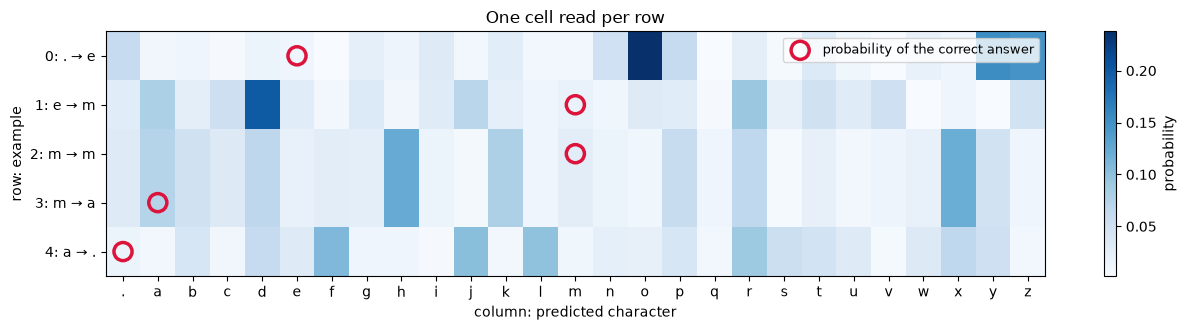

In [4]:
n = len(ys_small)
rows = torch.arange(n)
correct_probs = probs_small[rows, ys_small]
print("(row, column) pairs:", list(zip(rows.tolist(), ys_small.tolist())))
print("Same as the loop?   ", torch.allclose(correct_probs, loop_probs))
print("probs_small[:, ys_small]          :", tuple(probs_small[:, ys_small].shape), " ← WRONG here")
print("probs_small[torch.arange(n), ys]  :", tuple(correct_probs.shape))

fig, ax = plt.subplots(figsize=(13, 3.4))
im = ax.imshow(probs_small, aspect="auto", cmap="Blues")
ax.scatter(ys_small, rows, s=170, facecolors="none", edgecolors="crimson", linewidths=2.5,
           label="probability of the correct answer")
ax.set_xticks(range(27), [itos[j] for j in range(27)])
ax.set_yticks(range(n), [f"{i}: {a} → {b}" for i, (a, b) in enumerate(transitions)])
ax.set(xlabel="column: predicted character", ylabel="row: example", title="One cell read per row")
ax.legend(loc="upper right", fontsize=9); fig.colorbar(im, ax=ax, label="probability")
plt.tight_layout(); plt.show()

## 2. From the loss to its derivatives

The loss from notebook 02, written as a **function of `W`**:

$$
\mathcal L(W)=-\frac{1}{n}\sum_{i=0}^{n-1}\log\big(\mathrm{probs}(W)[i, y_i]\big).
$$

Two different matrices `W` give two different losses. We want to know **how the loss changes when we change one specific weight**. That is exactly what the partial derivative $\partial \mathcal L / \partial W_{a,b}$ tells us, the **local slope**:
- **positive**: increasing this weight makes the loss **go up**;
- **negative**: increasing this weight makes the loss **go down**;
- **close to zero**: this weight has almost no effect.

The **729 partial derivatives** form the **gradient**. Do not confuse them: `W` holds the weights, `W.grad` holds the **slopes of the loss** with respect to these weights.

The two functions below are exactly the forward pass from notebook 04 and the NLL from notebook 02 (they are also in `bigram.py`):

In [5]:
def forward_from_indices(x_indices, weights):
    """Forward pass of the neural bigram: indices -> one-hot -> logits -> probabilities."""
    encoded = F.one_hot(x_indices, num_classes=weights.shape[0]).float()  # (n, 27)
    logits = encoded @ weights                                            # (n, 27)
    counts = logits.exp()                                                 # (n, 27), all > 0
    return counts / counts.sum(dim=1, keepdim=True)                       # (n, 27), rows sum to 1


def nll_from_probs(probs, targets):
    """Mean NLL: -log of the probability given to the correct answer, averaged."""
    n = len(targets)
    correct_probs = probs[torch.arange(n), targets]   # (n,): one probability per example
    return -correct_probs.log().mean()                # scalar


print("Loss of W_demo on emma:", round(nll_from_probs(forward_from_indices(xs_small, W_demo), ys_small).item(), 4))

Loss of W_demo on emma: 3.7693


## 3. `requires_grad`, `backward()` and `W.grad`: who does what?

![Forward and backward](https://raw.githubusercontent.com/zenocode-org/ai-masterclass/main/en/chapter_1/figures/05_computation_graph.png)

To differentiate the loss, PyTorch must **record every operation** linking it to `W`: this is the **computation graph**.

- `W.requires_grad_(True)`: "I want the derivatives with respect to `W`". PyTorch then records every operation of the forward pass.
- `loss.backward()`: starts from the loss (a **scalar**) and **walks back through the graph**, applying the chain rule. This is **backpropagation**.
- `W.grad`: receives the gradient, of shape `(27, 27)`. These are neither probabilities nor the new values of `W`.
- `W.grad = None`: clears the previous gradient. Otherwise, PyTorch **adds up** the gradients of several calls to `backward()`.

**Crucial: `loss.backward()` does not change the weights.** It only computes the slopes. The change comes afterwards, and we write it ourselves.

In [6]:
W = W_demo.clone().requires_grad_(True)     # same start as above, but tracked by autograd

loss = nll_from_probs(forward_from_indices(xs_small, W), ys_small)
print("Gradient before backward:", W.grad)
loss.backward()
print("Gradient after backward: shape", tuple(W.grad.shape))

row, col = stoi["."], stoi["e"]
old_weight = W[row, col].item()
print(f"W['.', 'e']        = {old_weight:+.5f}   (the weight)")
print(f"∂loss/∂W['.', 'e'] = {W.grad[row, col].item():+.5f}   (the slope)")
print("Has the weight changed?", W[row, col].item() != old_weight)

Gradient before backward: None
Gradient after backward: shape (27, 27)
W['.', 'e']        = -0.02964   (the weight)
∂loss/∂W['.', 'e'] = -0.19754   (the slope)
Has the weight changed? False


The gradient of `W['.', 'e']` is **negative**: increasing this weight would **lower** the loss. That makes sense, because `. → e` is a real transition of `emma`. Increasing this score increases the probability of the correct answer.

### Check: `backward()` really computes a derivative

We can check one value of `W.grad` with a **finite difference**. We move a weight by $\pm\varepsilon$ and measure how much the loss changes:

$$
\frac{\partial\mathcal L}{\partial W_{a,b}} \approx \frac{\mathcal L(W_{a,b}+\varepsilon)-\mathcal L(W_{a,b}-\varepsilon)}{2\varepsilon}.
$$

This method needs two forward passes **per weight**. It is for **checking**, not for training. For 729 weights, it would take 1,458 forward passes. A single `backward()` computes **all** the derivatives at once.

In [7]:
eps = 1e-3
with torch.no_grad():
    W_plus, W_minus = W.detach().clone(), W.detach().clone()
    W_plus[row, col] += eps
    W_minus[row, col] -= eps
    l_plus = nll_from_probs(forward_from_indices(xs_small, W_plus), ys_small)
    l_minus = nll_from_probs(forward_from_indices(xs_small, W_minus), ys_small)

finite_slope = ((l_plus - l_minus) / (2 * eps)).item()
print(f"Finite difference: {finite_slope:+.6f}")
print(f"backward()       : {W.grad[row, col].item():+.6f}")
assert abs(finite_slope - W.grad[row, col].item()) < 1e-3

Finite difference: -0.197649
backward()       : -0.197543


### What `backward()` computes, by hand

You know how to differentiate: let's do it. For one example with correct answer $y$, and $p = \mathrm{softmax}(z)$:

$$
\mathcal L_i = -\log p_y = -z_y + \log\sum_k e^{z_k}
\qquad\Rightarrow\qquad
\frac{\partial \mathcal L_i}{\partial z_j} = p_j - \mathbb 1[j = y].
$$

Averaging over the $n$ examples, and since `logits = xenc @ W`:

$$
\frac{\partial \mathcal L}{\partial\,\mathrm{logits}} = \frac{\mathrm{probs} - \mathrm{one\_hot}(y)}{n},
\qquad
\frac{\partial \mathcal L}{\partial W} = \mathrm{xenc}^\top\,\frac{\partial \mathcal L}{\partial\,\mathrm{logits}}.
$$

**Interpretation:**
- the **correct answer** gets a slope $p_y - 1 < 0$: its score **goes up** at the update;
- **each wrong answer** gets a slope $p_j > 0$, proportional to its probability: its score **goes down**, all the more as the model believed in it;
- the rows of `W` for characters **absent** from the inputs get a **zero** gradient.

In [8]:
xenc = F.one_hot(xs_small, 27).float()
with torch.no_grad():
    probs = forward_from_indices(xs_small, W)
    dlogits = (probs - F.one_hot(ys_small, 27).float()) / len(ys_small)
    dW = xenc.T @ dlogits

print("Hand-computed gradient == W.grad?", torch.allclose(dW, W.grad, atol=1e-6))
active_rows = (W.grad.abs().sum(dim=1) > 0).nonzero().flatten().tolist()
print("Rows of W that receive a gradient:", [itos[i] for i in active_rows], "(the inputs of 'emma')")

Hand-computed gradient == W.grad? True
Rows of W that receive a gradient: ['.', 'a', 'e', 'm'] (the inputs of 'emma')


## 4. The update: subtract `learning_rate × grad`

To **lower** the loss, we take a step in the direction **opposite** to the gradient:

$$
\boxed{W_{\text{new}} = W_{\text{old}} - \eta\,\nabla_W\mathcal L}
$$

$\eta$ (`learning_rate`) sets the **step size**, not its direction:
- **small**: safe but slow progress;
- **larger**: faster progress;
- **too large**: we overshoot the good region, oscillate, or diverge.

Example with a single weight: `W[a,b] = 0.40`, `W.grad[a,b] = +0.20`, `lr = 0.1` gives $0.40 - 0.1\times0.20 = 0.38$. Positive gradient, so the weight **decreases**. An update changes **all** the weights, each according to its own slope.

The direction $-\nabla\mathcal L$ lowers the loss **locally**, for a small enough step. A very large step comes with no guarantee.

In [9]:
print(f"Starting loss: {loss.item():.4f}")
for lr in [0.0, 0.1, 1.0, 10.0, 100.0, 1000.0]:
    with torch.no_grad():
        l = nll_from_probs(forward_from_indices(xs_small, W - lr * W.grad), ys_small).item()
    print(f"  learning_rate = {lr:>6} → loss after ONE step = {l:.4f}")

Starting loss: 3.7693
  learning_rate =    0.0 → loss after ONE step = 3.7693
  learning_rate =    0.1 → loss after ONE step = 3.7492
  learning_rate =    1.0 → loss after ONE step = 3.5694
  learning_rate =   10.0 → loss after ONE step = 1.9317
  learning_rate =  100.0 → loss after ONE step = 0.3135
  learning_rate = 1000.0 → loss after ONE step = nan


On only 5 examples, the loss keeps dropping up to `lr = 100` (0.31!). With so little data, the model can almost memorize it in one big step. With `1000`, the logits become huge, `exp` overflows and the loss is `nan`: the step is absurd. On the whole corpus (notebook 06), useful steps will be much more modest.

We now take **a real step**. We write it under `torch.no_grad()`: the update does not need to be recorded in the computation graph, since it is not an operation of the model.

In [10]:
lr = 1.0
with torch.no_grad():
    W -= lr * W.grad

loss_after = nll_from_probs(forward_from_indices(xs_small, W), ys_small)
print(f"Loss before: {loss.item():.4f}  →  after one step: {loss_after.item():.4f}")
print(f"W['.', 'e']: {old_weight:+.4f} → {W[row, col].item():+.4f}")
assert loss_after.item() < loss.item()

Loss before: 3.7693  →  after one step: 3.5694
W['.', 'e']: -0.0296 → +0.1679


## Summary: one learning iteration

| step | code | role |
|---|---|---|
| forward | `probs = forward_from_indices(xs, W)` | predict |
| loss | `loss = nll_from_probs(probs, ys)` | score |
| reset | `W.grad = None` | avoid accumulating gradients |
| backward | `loss.backward()` | compute the 729 slopes |
| update | `W -= lr * W.grad` under `no_grad` | correct the weights |

**Check your understanding:**
1. Does `loss.backward()` change `W`? → No, it fills `W.grad`.
2. If `W.grad[a,b] > 0`, what happens to `W[a,b]`? → It **decreases** (minus sign).
3. Why did only 4 rows of `W` receive a gradient? → Only `.`, `e`, `m` and `a` are **inputs** of `emma`.

**Notebook 06:** repeat these five steps on the 228,146 bigrams of the corpus and see whether `W` recovers the table `P`.

## References
- D. E. Rumelhart, G. E. Hinton and R. J. Williams, [*Learning representations by back-propagating errors*](https://www.nature.com/articles/323533a0), Nature, 1986.
- Andrej Karpathy, [*The spelled-out intro to neural networks and backpropagation: building micrograd*](https://www.youtube.com/watch?v=VMj-3S1tku0) (2022): backpropagation recoded from scratch.
- 3Blue1Brown, [*Backpropagation calculus*](https://www.youtube.com/watch?v=tIeHLnjs5U8): the visual intuition of the chain rule.
- I. Goodfellow, Y. Bengio and A. Courville, [*Deep Learning*](https://www.deeplearningbook.org/), 2016, sections 4.3 (gradient descent) and 6.5 (backpropagation).
- PyTorch documentation: [*A Gentle Introduction to torch.autograd*](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html).